In [7]:
!pip install transformers torch torchvision pillow

In [ ]:
#image classification using pretrained models

Saving ai-engineer.jpg to ai-engineer.jpg


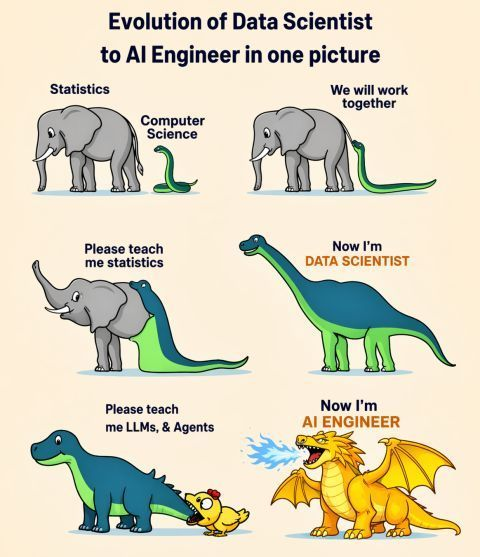

In [3]:
from google.colab import files
from PIL import Image

uploaded = files.upload()

image = Image.open(list(uploaded.keys())[0]).convert("RGB")

image

In [4]:
from transformers import CLIPProcessor
from transformers import CLIPModel

model = CLIPModel.from_pretrained(
    "openai/clip-vit-base-patch32"
)

processor = CLIPProcessor.from_pretrained(
    "openai/clip-vit-base-patch32"
)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

In [5]:
labels = [
    "cat",
    "dog",
    "car",
    "bicycle",
    "horse"
]

inputs = processor(
    text=labels,
    images=image,
    return_tensors="pt",
    padding=True
)

outputs = model(**inputs)

logits = outputs.logits_per_image

probs = logits.softmax(dim=1)

print(probs)

tensor([[0.0621, 0.0373, 0.2302, 0.1682, 0.5022]], grad_fn=<SoftmaxBackward0>)


In [ ]:
#image captioning

In [6]:
from transformers import BlipProcessor
from transformers import BlipForConditionalGeneration

processor = BlipProcessor.from_pretrained(
    "Salesforce/blip-image-captioning-base"
)

model = BlipForConditionalGeneration.from_pretrained(
    "Salesforce/blip-image-captioning-base"
)

inputs = processor(image, return_tensors="pt")

out = model.generate(**inputs)

caption = processor.decode(out[0], skip_special_tokens=True)

print(caption)

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/transformers/generation/utils.py:1954: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


a poster with different types of dinosaurs
